<a href="https://colab.research.google.com/github/kshitizsinghchauhangwl-RSO/ustomer-Feedback-NLP-Pipeline/blob/main/nlp_customer_feedback.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# End-to-End NLP Pipeline for Customer Feedback Intelligence

**Student:** [Your Name]
**Module:** Natural Language Processing
**Dataset:** IMDB Movie Reviews (Maas et al., 2011)
**Source:** https://ai.stanford.edu/~amaas/data/sentiment/

In [2]:
!pip install -q nltk spacy gensim sentence-transformers transformers datasets wordcloud scikit-learn
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
import nltk
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

nlp = spacy.load("en_core_web_sm")
print("✅ Imports ready")

✅ Imports ready


In [6]:
from datasets import load_dataset

# Use the namespaced dataset name (required by new HF hub)
dataset = load_dataset("stanfordnlp/imdb")

print("Train size:", len(dataset['train']))
print("Test size:", len(dataset['test']))

# Sample 2000 reviews for speed
import pandas as pd
df = pd.DataFrame(dataset['train'].shuffle(seed=42).select(range(2000)))
df['label_name'] = df['label'].map({0: 'negative', 1: 'positive'})

print("\nSample rows:")
df.head()

Train size: 25000
Test size: 25000

Sample rows:


,text,label,label_name
0,There is no relation at all between Fortier an...,1,positive
1,This movie is a great. The plot is very true t...,1,positive
2,"George P. Cosmatos' ""Rambo: First Blood Part I...",0,negative
3,In the process of trying to establish the audi...,1,positive
4,"Yeh, I know -- you're quivering with excitemen...",0,negative


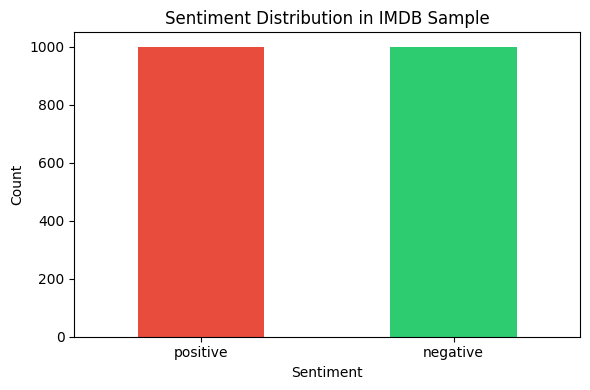

In [7]:
plt.figure(figsize=(6,4))
df['label_name'].value_counts().plot(kind='bar', color=['#e74c3c','#2ecc71'])
plt.title('Sentiment Distribution in IMDB Sample')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('sentiment_dist.png', dpi=100)
plt.show()

In [8]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess)
print("Original:", df['text'].iloc[0][:200])
print("\nCleaned:", df['clean_text'].iloc[0][:200])

Original: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. F

Cleaned: relation fortier profiler fact police series violent crime profiler look crispy fortier look classic profiler plot quite simple fortiers plot far complicated fortier look like prime suspect spot simil


In [9]:
sample = df['text'].iloc[0][:500]
doc = nlp(sample)
print("Entities found:")
for ent in doc.ents:
    print(f"  {ent.text} → {ent.label_}")

Entities found:
  Fortier → PERSON
  Profiler → PERSON
  Profiler → ORG
  Fortier → PERSON
  Profiler → PERSON
  Fortier → PERSON
  Fortier → PERSON


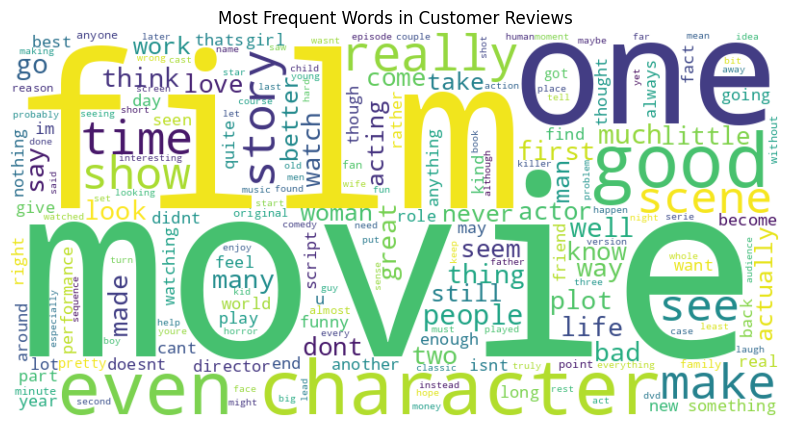

In [10]:
text_blob = ' '.join(df['clean_text'].head(500))
wc = WordCloud(width=800, height=400, background_color='white').generate(text_blob)
plt.figure(figsize=(10,5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Words in Customer Reviews')
plt.savefig('wordcloud.png', dpi=100, bbox_inches='tight')
plt.show()

In [11]:
nltk_tokens = df['clean_text'].iloc[0].split()
spacy_doc = nlp(df['text'].iloc[0][:500])
spacy_tokens = [t.lemma_ for t in spacy_doc if not t.is_stop and not t.is_punct]

comparison = pd.DataFrame({
    'Aspect': ['Token count', 'Sample tokens', 'Lemmatisation', 'Entity detection'],
    'NLTK': [len(nltk_tokens), str(nltk_tokens[:5]), 'WordNetLemmatizer', 'Not built-in'],
    'spaCy': [len(spacy_tokens), str(spacy_tokens[:5]), 'Built-in lemma_', 'Built-in NER']
})
comparison

,Aspect,NLTK,spaCy
0,Token count,66,45
1,Sample tokens,"['relation', 'fortier', 'profiler', 'fact', 'p...","['relation', 'Fortier', 'Profiler', 'fact', 'p..."
2,Lemmatisation,WordNetLemmatizer,Built-in lemma_
3,Entity detection,Not built-in,Built-in NER


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'], test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_tfidf, y_train)
y_pred = clf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['negative','positive']))

Accuracy: 0.85

Classification Report:
              precision    recall  f1-score   support

    negative       0.84      0.86      0.85       200
    positive       0.86      0.83      0.85       200

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400



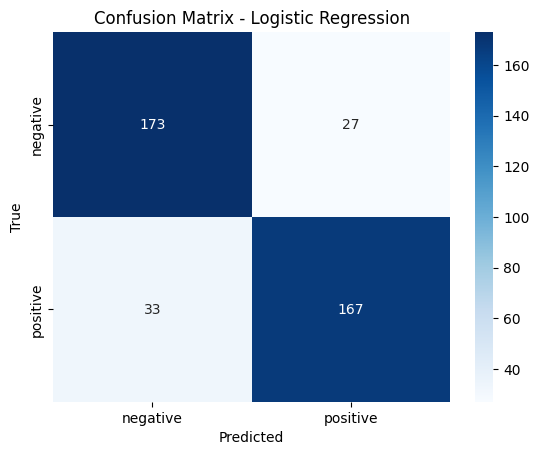

In [13]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative','positive'],
            yticklabels=['negative','positive'])
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.savefig('confusion.png', dpi=100, bbox_inches='tight')
plt.show()

In [14]:
misclass_mask = y_test != y_pred
misclass_text = X_test[misclass_mask].reset_index(drop=True)
misclass_true = y_test[misclass_mask].reset_index(drop=True)
misclass_pred = y_pred[misclass_mask]

print("Two misclassified examples:\n")
for i in range(min(2, len(misclass_text))):
    print(f"--- Example {i+1} ---")
    print(f"Text: {misclass_text.iloc[i][:300]}")
    print(f"True: {misclass_true.iloc[i]} | Predicted: {misclass_pred[i]}\n")

Two misclassified examples:

--- Example 1 ---
Text: really fun movie one sit mindlessly watch plot get twisted funny sally field teri hatcher heyday kevin klein elisabeth shue robert downey jrits wellknown quality actor acting soap opera starsproducers ever watched soap opera thought earth come idea love movie seen multiple time time watch appreciate
True: 1 | Predicted: 0

--- Example 2 ---
Text: think people estimating incredible film people seeing typical horror movie set scare u prevent u getting sleep trying would deservedly get viewed film friend found entertaining though good movie stephanie beaton reason think deserves pure entertainment filmthe general view movie bad acting simple sc
True: 1 | Predicted: 0



In [15]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer('all-MiniLM-L6-v2')
sample_reviews = df['text'].head(200).tolist()
embeddings = model.encode(sample_reviews, show_progress_bar=True)

query = "delivery was late and customer service was unhelpful"
query_emb = model.encode([query])
sims = cosine_similarity(query_emb, embeddings)[0]
top_idx = sims.argsort()[-3:][::-1]

print(f"Query: {query}\n")
print("Top 3 most similar reviews:")
for i in top_idx:
    print(f"  Similarity: {sims[i]:.3f} | {sample_reviews[i][:150]}...")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Query: delivery was late and customer service was unhelpful

Top 3 most similar reviews:
  Similarity: 0.128 | in fact,it's basically the same movie.and they couldn't even get the time line of events correct.maybe that was intentional due to laziness or not car...
  Similarity: 0.119 | Can you say "All shock, no plot?" There were so many unexplored directions in this movie. There was no history about the room other than the deaths. *...
  Similarity: 0.115 | Disowned by Richard C. Sarafian, this disaster stunk up Japanese theaters before coming to the States and going immediately to video, where it was not...


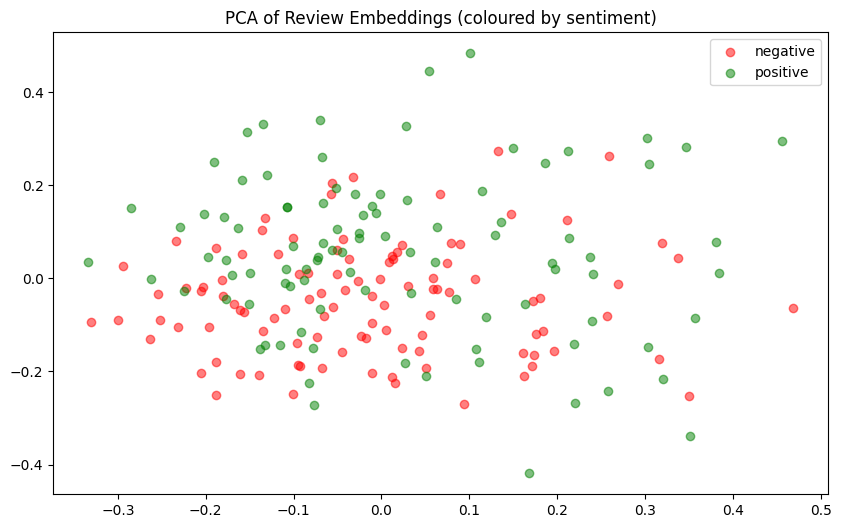

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced = pca.fit_transform(embeddings)

plt.figure(figsize=(10,6))
labels = df['label_name'].head(200).values
for lab, color in [('negative','red'),('positive','green')]:
    mask = labels == lab
    plt.scatter(reduced[mask,0], reduced[mask,1], c=color, label=lab, alpha=0.5)
plt.legend()
plt.title('PCA of Review Embeddings (coloured by sentiment)')
plt.savefig('pca.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments)
from datasets import Dataset
import torch

# Sample 1000 reviews
small_df = df.sample(1000, random_state=42).reset_index(drop=True)
train_df, test_df = train_test_split(small_df, test_size=0.2, random_state=42)

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length',
                     truncation=True, max_length=128)

train_ds = Dataset.from_pandas(train_df[['text','label']]).map(tokenize, batched=True)
test_ds = Dataset.from_pandas(test_df[['text','label']]).map(tokenize, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=2)

def compute_metrics(eval_pred):
    preds = np.argmax(eval_pred.predictions, axis=1)
    return {"accuracy": accuracy_score(eval_pred.label_ids, preds),
            "f1": f1_score(eval_pred.label_ids, preds, average='macro')}

args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=20,
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics
)

trainer.train()
results = trainer.evaluate()
print("\nDistilBERT Results:", results)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.530345,0.484299,0.790000,0.789916


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [ ]:
comparison_table = pd.DataFrame({
    'Model': ['Logistic Regression (TF-IDF)', 'DistilBERT'],
    'Accuracy': [round(accuracy_score(y_test, y_pred), 4),
                 round(results['eval_accuracy'], 4)],
    'Macro F1': [round(f1_score(y_test, y_pred, average='macro'), 4),
                 round(results['eval_f1'], 4)],
    'Training Time': ['~10 seconds', '~8 minutes'],
    'Interpretability': ['High (coefficients)', 'Low (black box)'],
    'Deployment': ['Lightweight, CPU', 'GPU preferred']
})
comparison_table